# Azerbaijani Text Analysis: Sentiment and Topic Modeling

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset

pd.set_option("display.max_colwidth", 200)

## Data Preparation

In [2]:
ds = load_dataset("hajili/azerbaijani_review_sentiment_classification")
train_df = ds["train"].to_pandas()
test_df  = ds["test"].to_pandas()

README.md:   0%|          | 0.00/222 [00:00<?, ?B/s]

train.csv:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/1.25M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/127537 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/31885 [00:00<?, ? examples/s]

In [3]:
print("train:", len(train_df), "| test:", len(test_df))

train: 127537 | test: 31885


The dataset is loaded and the sizes of train and test are checked. This confirms that the correct dataset is loaded and that nothing is missing. The sizes match the task description.

---
Dataset yüklənir və train ilə test-in ölçüləri yoxlanılır. Məqsəd düzgün dataset-in yükləndiyini və heç nəyin əskik olmadığını təsdiqləməkdir. Ölçülər tapşırıqdakı təsvirə uyğundur.

In [4]:
train_df.isnull().sum()

content    3
score      0
upvotes    0
dtype: int64

Missing values are checked to find reviews without any text. A model cannot learn sentiment from an empty review, so such rows must be known before cleaning. Only a few empty reviews exist, and they are removed later.

---
Mətni olmayan rəyləri tapmaq üçün boş dəyərlər yoxlanılır. Model boş rəydən sentiment öyrənə bilməz, ona görə bu sətirlər təmizləmədən əvvəl bilinməlidir. Boş rəylər çox azdır və sonradan silinir.

In [5]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 127537 entries, 0 to 127536
Data columns (total 3 columns):
 #   Column   Non-Null Count   Dtype 
---  ------   --------------   ----- 
 0   content  127534 non-null  object
 1   score    127537 non-null  int64 
 2   upvotes  127537 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 2.9+ MB


In [6]:
train_df.head()

,content,score,upvotes
0,Çox qəşəy,5,0
1,Men niye nomre ile qeydiyatdan kece bilmirem......kecirem mesaj gelir ki Bu tetbiq işlemir....... islemirse niye camatin başin xarab edirsizz,1,0
2,Salam. Mən yukluyə bilmirəm. Necə kömək edə bilərsiz?,5,0
3,cox gözəl,5,1
4,Xaiş edirem bu problemi hell edinde həftədə 2 dəfə çarx gəlsin,5,0


score
1    0.113
2    0.015
3    0.022
4    0.036
5    0.814
Name: proportion, dtype: float64


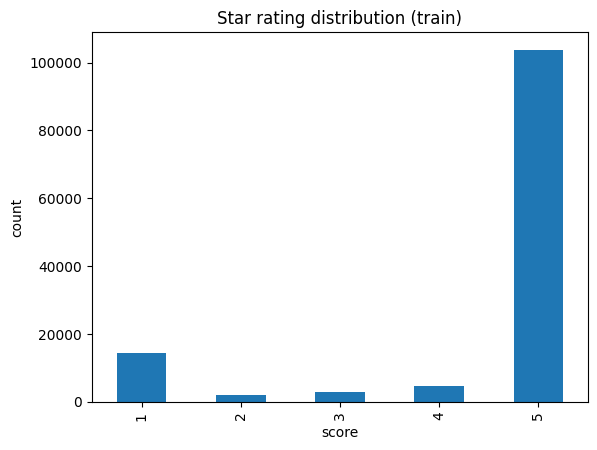

In [7]:
print(train_df["score"].value_counts(normalize=True).sort_index().round(3))
train_df["score"].value_counts().sort_index().plot(kind="bar")
plt.title("Star rating distribution (train)")
plt.xlabel("score")
plt.ylabel("count")
plt.show()

The results indicate that the data is highly imbalanced. '5-star' reviews account for 81.4% of the total, '1-star' reviews make up 11.3%, while '2-3-4-star' reviews constitute only 7.3%. The training set needs to be balanced.

---
Çıxan nəticə data güclü balanssız olduğunu göstərir. "5 ulduz" rəylərin 81.4%-ni təşkil edir, "1 ulduz" 11.3%, "2-3-4 ulduz" isə cəmi 7.3%-dir.
Train hissəsi balanslaşdırılmalıdır.

In [8]:
print(train_df["content"].astype(str).str.len().describe())

count    127537.000000
mean         30.389220
std          51.815437
min           1.000000
25%           5.000000
50%          10.000000
75%          34.000000
max        1987.000000
Name: content, dtype: float64


Review length is checked to understand what a typical text looks like. This decides the maximum token length for the model and whether short reviews should be kept. Most reviews are very short, so a small token limit is enough and short reviews are not removed.

---
Tipik mətnin necə göründüyünü anlamaq üçün rəy uzunluğuna baxılır. Bu, modelin maksimum token uzunluğunu və qısa rəylərin saxlanıb-saxlanmayacağını müəyyən edir. Rəylərin çoxu çox qısadır, ona görə kiçik token limiti kifayətdir və qısa rəylər silinmir.

In [9]:
print("Raw duplicates:", train_df.duplicated(subset="content").sum())

Raw duplicates: 62850


Reviews with identical text are counted before any cleaning. This shows how large the repetition problem is and whether it needs a separate decision. Repetition is very high, so duplicates are handled later after cleaning.

---
Təmizləmədən əvvəl mətni eyni olan rəylər sayılır. Bu, təkrar probleminin nə qədər böyük olduğunu və ayrıca qərar tələb edib-etmədiyini göstərir. Təkrar çox yüksəkdir, ona görə təkrarlar təmizləmədən sonra idarə olunur.

In [10]:
def clean(text):
    if not isinstance(text, str):
        return ""

    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

The `clean()` function reduces noise - it removes links, shortens exaggerated repeated characters and fixes extra spaces. Emojis, letter case and common words are kept on purpose, because they carry sentiment and the XLM-R tokenizer can handle them. This cell only defines the function; it is applied in the next cells.

---
`clean()` funksiyası "səs-küyü" azaldır - linkləri silir, şişirdilmiş təkrar simvolları qısaldır və artıq boşluqları düzəldir. Emojilər, hərf registri və ümumi sözlər qəsdən saxlanılır, çünki sentiment daşıyırlar və XLM-R tokenizeri onları özü idarə edir. Bu xana yalnız funksiyanı yaradır, növbəti xanalarda tətbiq olunur.

In [11]:
train_df["text"] = train_df["content"].apply(clean)

In [12]:
test_df["text"]  = test_df["content"].apply(clean)

In [13]:
train_df[["content", "text"]].sample(8, random_state=1)

,content,text
11474,Əladı,Əladı
12114,Evde qala görə 6 GB verirsiz,Evde qala görə 6 GB verirsiz
114861,Əladır super dir. Bu proqramı düzəltməkdə kimin əziyyəti keçirsə minnətdarlığımı bildirirəm.♥♥♥,Əladır super dir. Bu proqramı düzəltməkdə kimin əziyyəti keçirsə minnətdarlığımı bildirirəm.♥♥
77349,Ellaaaa,Ellaa
20535,Əla,Əla
49933,👍,👍
53399,✅✅✅,✅✅
34856,Əla,Əla


The cleaned text is compared with the original on random examples. The same cleaning is applied to train and test, so the model always sees the same text format. The meaning of the reviews is preserved after cleaning.

---
Təmizlənmiş mətn təsadüfi nümunələrdə orijinalla müqayisə edilir. Eyni təmizləmə train və test-ə tətbiq olunur ki, model həmişə eyni mətn formatı ilə qarşılaşsın. Təmizləmədən sonra rəylərin mənası pozulmur.

In [14]:
has_content = r"\w|[^\x00-\x7F]"

bad_train = train_df[~train_df["text"].str.contains(has_content, regex=True)]
bad_test  = test_df[~test_df["text"].str.contains(has_content, regex=True)]

print("To be dropped -> train:", len(bad_train), "| test:", len(bad_test))
print(bad_train["text"].value_counts().head(10))

To be dropped -> train: 37 | test: 11
text
.      5
..     4
       3
. .    3
:-)    3
??     3
:)     2
@      2
:/     1
:-*    1
Name: count, dtype: int64


In [15]:
print("Before -> train:", len(train_df), "| test:", len(test_df))

train_df = train_df[train_df["text"].str.contains(has_content, regex=True)].reset_index(drop=True)
test_df  = test_df[test_df["text"].str.contains(has_content, regex=True)].reset_index(drop=True)

print("After  -> train:", len(train_df), "| test:", len(test_df))

Before -> train: 127537 | test: 31885
After  -> train: 127500 | test: 31874


In [16]:
print(train_df["text"].str.len().min())

1


In [17]:
print(train_df.isna().sum())

content    0
score      0
upvotes    0
text       0
dtype: int64


During the 'empty and meaningless reviews' cleaning process, reviews that were empty, contained only punctuation, or had no letters, numbers, or emojis were removed. Short reviews such as "hə", "ok", and "👍" were kept since they represent valid responses.

---
"Boş və mənasız rəylər" təmizləmədən sonra hərf, rəqəm və ya emoji olmayan, boş və ya yalnız durğu işarəsindən ibarət rəylər silindi. "hə", "ok", "👍" kimi qısa rəylər real cavab olduğu üçün saxlanıldı.

In [18]:
dup_count = train_df.duplicated(subset="text").sum()
print("Duplicates (train, by text):", dup_count)
print(f"Share of train: {dup_count / len(train_df):.1%}")

print(train_df["text"].value_counts().head(10))

Duplicates (train, by text): 63602
Share of train: 49.9%
text
Əla          13288
Super         6980
👍             4292
👍👍            2154
super         1999
Yaxşı          862
Eladi          739
əla            690
Çox gözəl      689
Əlaa           681
Name: count, dtype: int64


Duplicates are counted again on the cleaned text, because the model sees only this text. Repeated reviews are mostly short real answers like `Əla` or `👍`, written by different users, not data errors. So removing them is a modeling choice, not a data fix.

---
Təkrarlar yenidən təmizlənmiş mətn üzərində sayılır, çünki model yalnız bu mətni görür. Təkrarlanan rəylər əsasən `Əla`, `👍` kimi fərqli istifadəçilərin yazdığı qısa real cavablardır, data xətası deyil. Ona görə onları atmaq data düzəlişi yox, modelləşdirmə seçimidir.

In [19]:
print("Before -> train:", len(train_df))

train_df = train_df.drop_duplicates(subset="text").reset_index(drop=True)

print("After  -> train:", len(train_df))
print("Remaining duplicates:", train_df.duplicated(subset="text").sum())

Before -> train: 127500
After  -> train: 63898
Remaining duplicates: 0


Each text is kept only once in the train set. This prevents the model from memorizing frequent phrases and prevents the same review from appearing in both train and validation. The test set is not changed, so it keeps the real distribution.

---
Train dəstində hər mətn yalnız bir dəfə saxlanılır. Bu, modelin tez-tez təkrarlanan ifadələri əzbərləməsinin və eyni rəyin həm train, həm validation-da olmasının qarşısını alır. Test dəsti dəyişdirilmir, beləliklə real paylanmanı saxlayır.

In [20]:
print(train_df["score"].value_counts(normalize=True).sort_index().round(3))

score
1    0.203
2    0.027
3    0.035
4    0.046
5    0.689
Name: proportion, dtype: float64


In [21]:
seen = test_df["text"].isin(set(train_df["text"]))
test_df["seen_in_train"] = seen

print(f"Test reviews also in train: {seen.sum()} ({seen.mean():.1%})")
print(f"New (unseen) test reviews : {(~seen).sum()} ({(~seen).mean():.1%})")

print(test_df.loc[seen, "text"].value_counts().head(10))

Test reviews also in train: 16592 (52.1%)
New (unseen) test reviews : 15282 (47.9%)
text
Əla          3317
Super        1676
👍            1042
👍👍            543
super         475
Yaxşı         200
əla           192
Çox gözəl     181
Eladi         178
Superdi       171
Name: count, dtype: int64


In [22]:
print("Full test:")
print(test_df["score"].value_counts(normalize=True).sort_index().round(3))

print("\nUnseen only:")
print(test_df.loc[~test_df["seen_in_train"], "score"].value_counts(normalize=True).sort_index().round(3))

Full test:
score
1    0.113
2    0.014
3    0.021
4    0.037
5    0.814
Name: proportion, dtype: float64

Unseen only:
score
1    0.208
2    0.026
3    0.036
4    0.047
5    0.682
Name: proportion, dtype: float64


Each test review is marked as seen or unseen in the train data. Many test reviews are common short phrases that also exist in train, which can make the results look better than they are. Therefore, the evaluation is later reported on both the full test set and only on new reviews.

---
Hər test rəyi train datasında görünüb-görünmədiyinə görə işarələnir. Test rəylərinin çoxu train-də də olan ümumi qısa ifadələrdir və bu, nəticələri olduğundan yaxşı göstərə bilər. Ona görə qiymətləndirmə sonra həm tam test, həm də yalnız yeni rəylər üzərində verilir.

In [23]:
print(train_df.isna().sum())
print(test_df.isna().sum())
print("Remaining duplicates (train):", train_df.duplicated(subset="text").sum())
print("train:", len(train_df), "| test:", len(test_df))

train_df.to_csv("train_clean.csv", index=False)
test_df.to_csv("test_clean.csv", index=False)

content    0
score      0
upvotes    0
text       0
dtype: int64
content          0
score            0
upvotes          0
text             0
seen_in_train    0
dtype: int64
Remaining duplicates (train): 0
train: 63898 | test: 31874


## Label Definition

In [24]:
def to_label(score):
    if score <= 2: return 0   # negative
    if score == 3: return 1   # neutral
    return 2                  # positive

label_names = {0: "negative", 1: "neutral", 2: "positive"}

for df in [train_df, test_df]:
    df["label"] = df["score"].apply(to_label)

Star ratings are converted into three sentiment classes - negative (1-2), neutral (3) and positive (4-5). The model learns classes, not stars, and this is the most common and easy to explain rule. The same rule is used for train and test so that the evaluation is fair.

---
Ulduz balları, üç sentiment sinfinə çevrilir - mənfi (1-2), neytral (3) və müsbət (4-5). Model ulduzları yox, sinifləri öyrənir və bu, ən yayılmış və izahı asan qaydadır. Eyni qayda train və test-ə tətbiq olunur ki, qiymətləndirmə ədalətli olsun.

In [25]:
print(train_df["label"].map(label_names).value_counts(normalize=True).round(3))
print(test_df["label"].map(label_names).value_counts(normalize=True).round(3))
print(train_df["label"].map(label_names).value_counts())

label
positive    0.735
negative    0.230
neutral     0.035
Name: proportion, dtype: float64
label
positive    0.851
negative    0.128
neutral     0.021
Name: proportion, dtype: float64
label
positive    46954
negative    14678
neutral      2266
Name: count, dtype: int64


The class distribution is checked to see how balanced the labels are. The positive class dominates and the neutral class is very small.

---
Etiketlərin nə qədər balanslı olduğunu görmək üçün sinif paylanması yoxlanılır. Müsbət sinif üstünlük təşkil edir, neytral sinif isə çox kiçikdir.

In [26]:
for lab in [0, 1, 2]:
    print(f"\n=== {label_names[lab]} ===")
    print(train_df[train_df["label"] == lab][["text", "score"]].sample(10, random_state=1).to_string())


=== negative ===
                                                                                                                                                                                                            text  score
20788                                                                                                                                                                                             Sistem acılmır      2
36151                                                                            Pravamda AE kateqoryası var.Ama bu proqranda yoxdu bir zehmet düzeliş edin bura qoşla bilmirem bir cavab deyin nece edim qoşlum      1
39172                                                                                                                                                                                         AllaH nervilənirəm      1
44507  Senin praqram tertib edenin klaviaturasi dagilsin pulla mekteb oxuyub pulla ise girende bax bele eybecer yenili

A few random reviews from each class are read to see if the stars match the text. Negative reviews are clear complaints, neutral reviews are mostly mild complaints or mixed opinions, and positive reviews are mostly praise with a few exceptions. The sample is small, so it shows a general direction and not an exact rate.

---
Ulduzların mətnə uyğun olub-olmadığını görmək üçün hər sinifdən bir neçə təsadüfi rəy oxunur. Mənfi rəylər aydın şikayətdir, neytral rəylər əsasən yumşaq şikayət və qarışıq fikirlərdir, müsbət rəylər isə bir neçə istisna ilə tərifdir. Nümunə kiçikdir, ona görə dəqiq faiz yox, ümumi istiqamət göstərir.

In [27]:
from collections import Counter

def top_words(df, label, n=25):
    words = " ".join(df[df["label"] == label]["text"].str.lower()).split()
    return Counter(words).most_common(n)

for lab in [0, 1, 2]:
    print(label_names[lab].upper(),"-----", top_words(train_df, lab))

NEGATIVE ----- [('bu', 3177), ('bir', 2037), ('çox', 1896), ('pis', 1156), ('cox', 1093), ('olmur', 1040), ('salam', 930), ('1', 908), ('pul', 902), ('nə', 803), ('proqram', 781), ('ki', 766), ('amma', 742), ('və', 701), ('sonra', 682), ('mən', 677), ('heç', 658), ('ne', 653), ('deyir', 610), ('qeydiyyatdan', 595), ('daxil', 586), ('var', 584), ('men', 578), ('kimi', 575), ('da', 525)]
NEUTRAL ----- [('bu', 303), ('bir', 263), ('amma', 221), ('salam', 218), ('çox', 207), ('yaxşı', 177), ('mən', 136), ('pul', 135), ('olar', 132), ('və', 124), ('olmasa', 114), ('olmur', 113), ('tez', 112), ('daha', 111), ('ki', 111), ('ama', 110), ('cox', 93), ('var', 90), ('proqram', 90), ('daxil', 89), ('men', 87), ('olsa', 87), ('da', 85), ('edirəm', 85), ('üçün', 84)]
POSITIVE ----- [('çox', 8335), ('cox', 5142), ('əla', 3805), ('bir', 3649), ('super', 3534), ('bu', 2962), ('gözəl', 2694), ('ela', 2391), ('salam', 2289), ('yaxşı', 2186), ('və', 2143), ('amma', 1725), ('olar', 1718), ('hər', 1387), ('

The most frequent words are listed for each class to see its vocabulary. Each class has its own typical words, such as complaints for negative and praise for positive. Spelling without special Azerbaijani letters is very common, which shows the noise in the data.

---
Hər sinfin lüğətini görmək üçün ən çox işlənən sözlər çıxarılır. Hər sinfin öz xarakterik sözləri var, məsələn mənfidə şikayət, müsbətdə tərif sözləri. Azərbaycan hərfləri olmadan yazılış çox yayılıb və bu, datadakı "səs-küyü" göstərir.

In [28]:
only_digits = train_df[train_df["text"].str.fullmatch(r"\d+")]
print(len(only_digits))
print(only_digits.groupby("text")["score"].agg(["count", "mean"]).sort_values("count", ascending=False).head(10))

3
      count  mean
text             
1         1   5.0
44        1   5.0
5         1   5.0


Reviews made only of digits are checked, because the token `1` appeared often in negative reviews. The goal was to see if users write their star rating inside the text. Almost no such reviews exist, so there is no direct leak from the star into the text.

---
`1` tokeni mənfi rəylərdə tez-tez çıxdığı üçün yalnız rəqəmdən ibarət rəylər yoxlanılır. Məqsəd istifadəçilərin öz ulduzunu mətnin içində yazıb-yazmadığını görmək idi. Belə rəylər demək olar ki, yoxdur, yəni ulduzun mətnə birbaşa sızması yoxdur.

In [29]:
neg_words = ["pis", "olmur", "işləmir", "islemir", "açılmır", "acilmir"]
pos_words = ["əla", "ela", "super", "gözəl", "gozel", "rahat"]

neg_pattern = r"\b(?:" + "|".join(neg_words) + r")\b"
pos_pattern = r"\b(?:" + "|".join(pos_words) + r")\b"

neg_in_pos = train_df[(train_df["label"] == 2) & train_df["text"].str.contains(neg_pattern, case=False, regex=True)]
pos_in_neg = train_df[(train_df["label"] == 0) & train_df["text"].str.contains(pos_pattern, case=False, regex=True)]

print("Positive label, negative words:", len(neg_in_pos))
print("Negative label, positive words:", len(pos_in_neg))
neg_in_pos[["text", "score"]].head(15)

Positive label, negative words: 1618
Negative label, positive words: 385


,text,score
68,Salam burda limitsiz internet trafiki varmi?*77#05#yes 13 azn .limitsiz intrenet yazilib.men indi basa dusmurem yalniz geceler limitsiz olr?seherler limitsiz olmur?ve sureti ne qədərdi ? Eger burd...,5
121,Milli on aparatinnan pul kocurmək olmur,5
213,"Applikasiya problemsizdir, ela! Ancaq bir neçə hesabı bir app-da idarə etmək olmur, xahish edirem bu problemi hell edesiniz, tesekkurler! 👍",4
259,Niye əmək pensiyası kartını daxil etmək olmur? Birdəfəlik şifrə niyə gəlmir,5
265,Proqram yuklemiwem açılmır niye beledi,5
341,Birbank tedbiqiniz yaxsi islemir bu tedbiqe duzelis edin,5
358,Pis deyil,5
369,Kartla qetdiyyatan keçirəm davam et sözünü vurandan sonra deyir xidmət müvəqəti olaraq işləmir həmişə belə edir haçan girəm belə yazır düzəldin bunu zəhmət olmasa amma əla proqramdı proqramlarda 1...,5
411,Salam 18 yaşdan aşağı digital kart açmaq olmur onu necə edə bilərəm,5
419,Belede pis deyil ama serfeli internet paketi yoxdu,5


A rough keyword filter is used to find possible contradictions between stars and text. The word lists were chosen by hand from the frequent-word output. It only shows suspicious cases and is not an exact measure, because it also catches negations like `pis deyil`.

---
Ulduz və mətn arasındakı mümkün ziddiyyətləri tapmaq üçün kobud açar söz süzgəci istifadə olunur. Söz siyahıları tezlik çıxışından əl ilə seçilib. O yalnız şübhəli halları göstərir və dəqiq ölçü deyil, çünki `pis deyil` kimi inkarları da tutur.

In [30]:
pos_in_neg[["text", "score"]].head(15)

,text,score
404,Əla proqramdır 👍👍,2
514,Salam Hərvaxtiniz Xeyirli Və Uğurlu Olsun Mən Düz 1 İldən Çoxdu Leobank Xidmətindən İstifadə Edirəm Şükür Allaha Heçbir Şikayətim Yoxdu Etirazimda Yoxdu MaşaAllah Min Kərəm MaşaAllah Olsun Çox Göz...,1
517,"Əla. Sizdən çox çox hədiyyələr istəyirik, kampanyalar istəyirik. Bakcell həmişə yekdir",2
643,ela proqramdi,1
700,Pox kimi sürücüləri var sürücüləri çox pisdi maşınları rahat deyil silin bunu bolt yüklüyün Vallah bolt bundan bin dəfə yaxşıdı,1
971,Ela proqram,1
1051,Faydalı kəşbeki köçürmək üçün tətbiq olunan minimum 10 AZNLİK limiti 5-ə endirilsə əla olardı..,1
1201,Kaş burdada Azercell deki kimi olardı pulsuz çarxlar çox gözəl olardı xaiş edirəm ki nara onu əlavə edəsiniz komen tome çıxsın deyə hshshshhshshshshshhshsgsgdhdhhdhdhdhdhdhhdhdhdhhrhdhdhdisksjdhjd...,1
1651,Super😍,1
1869,Salam məndə nar işlədirəm azərseldəki kimi çarx qoysaz əla olar həmdə çox adam istifadə edər nar mobildən sizə tövsüyyəm ! O yoxdu ona görə 1☆ bəsnizdi məndə keçəcəm azərselə!,1


The suspicious reviews are read to understand the contradictions. Some are real mismatches, such as praise with a low star, and some are filter errors or mixed texts. Decision: labels are kept as given by the stars, because the star is the user's own rating and changing labels by rules would add new errors. The remaining label noise is stated as a limitation.

---
Ziddiyyətləri anlamaq üçün şübhəli rəylər oxunur. Bir hissəsi həqiqi uyğunsuzluqdur, məsələn aşağı ulduzla verilmiş tərif, bir hissəsi isə süzgəcin səhvi və ya qarışıq mətnlərdir. Qərar- etiketlər ulduza əsasən saxlanılır, çünki ulduz istifadəçinin öz qiymətidir və etiketləri qaydalarla dəyişmək yeni səhvlər yaradar. Qalan etiket "səs-küyü" məhdudiyyət kimi qeyd olunur.

In [31]:
train_df.to_csv("train_labeled.csv", index=False)
test_df.to_csv("test_labeled.csv", index=False)
print(train_df["label"].value_counts().sort_index())

label
0    14678
1     2266
2    46954
Name: count, dtype: int64


## Split and Balancing

In [32]:
from sklearn.model_selection import train_test_split

train_part, val_df = train_test_split(train_df,test_size=0.15,random_state=42,
    stratify=train_df["label"],)
train_part = train_part.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("train_part:", len(train_part), "| val:", len(val_df), "| test:", len(test_df))
print(train_part["label"].map(label_names).value_counts())
print(val_df["label"].map(label_names).value_counts())

train_part: 54313 | val: 9585 | test: 31874
label
positive    39911
negative    12476
neutral      1926
Name: count, dtype: int64
label
positive    7043
negative    2202
neutral      340
Name: count, dtype: int64


The train data is split into a training part and a validation part, and the test set stays untouched. Validation is used to choose the best epoch during training, so the test result is not influenced by any choice. The split keeps the same class ratios, and duplicates were removed earlier, so the same text cannot be in both parts.

---
Train datası təlim hissəsinə və validation hissəsinə bölünür, test dəsti toxunulmaz qalır. Validation təlim zamanı ən yaxşı epoxu seçmək üçündür, ona görə test nəticəsinə heç bir seçim təsir etmir. Bölgü eyni sinif nisbətlərini saxlayır, təkrarlar isə əvvəl silinib, ona görə eyni mətn hər iki hissədə ola bilməz.

In [33]:
print(val_df["label"].map(label_names).value_counts(normalize=True).round(3))

label
positive    0.735
negative    0.230
neutral     0.035
Name: proportion, dtype: float64


The validation class distribution is checked. It is the same as in train and keeps the natural imbalance. This way, model selection is based on realistic data.

---
Validation-ın sinif paylanması yoxlanılır. O, train ilə eynidir və təbii balanssızlığı saxlayır. Beləliklə, model seçimi real vəziyyətə yaxın data üzərində aparılır.

In [34]:
MAX_PER_CLASS = 6000

parts = []
for lab, g in train_part.groupby("label"):
    n = min(len(g), MAX_PER_CLASS)
    parts.append(g.sample(n, random_state=42))

train_bal = pd.concat(parts).sample(frac=1, random_state=42).reset_index(drop=True)

print(train_bal["label"].map(label_names).value_counts())
print("train_bal:", len(train_bal))

label
positive    6000
negative    6000
neutral     1926
Name: count, dtype: int64
train_bal: 13926


Only the training part is balanced by limiting the two large classes and keeping all neutral reviews. Without balancing, a model can look good by always predicting positive, so balancing forces it to learn all three classes. The trade-off is that many samples are dropped and the real class frequencies are changed, which is why validation and test stay natural.

---
Yalnız təlim hissəsi balanslaşdırılır - iki böyük sinif məhdudlaşdırılır, neytral rəylərin hamısı saxlanılır. Balanslaşdırma olmasa, model həmişə müsbət deyərək yaxşı görünə bilər, ona görə balanslaşdırma onu üç sinfi də öyrənməyə məcbur edir. Məqsəd çoxlu nümunənin atılması və sinif tezliklərinin dəyişməsidir, buna görə validation və test təbii qalır.

In [35]:
train_bal.to_csv("train_bal.csv", index=False)
val_df.to_csv("val.csv", index=False)
print("saved")

saved


## Baseline Model

In [36]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(analyzer="char_wb",ngram_range=(2, 5),min_df=3,
        max_features=300000,sublinear_tf=True,)

X_train = tfidf.fit_transform(train_bal["text"])
X_val   = tfidf.transform(val_df["text"])

y_train = train_bal["label"]
y_val   = val_df["label"]

print(X_train.shape, X_val.shape)

(13926, 45827) (9585, 45827)


Text is converted into numbers using TF-IDF on character pieces. Character pieces were chosen because the data has many spelling variants like `çox` and `cox`, and such pieces keep variants close to each other. The vectorizer learns only from the training data and is only applied to validation, so no information leaks.

---
Mətn hərf parçaları üzərində TF-IDF ilə rəqəmlərə çevrilir. Hərf parçaları seçildi, çünki datada `çox` və `cox` kimi çoxlu yazılış variantı var və bu parçalar variantları bir-birinə yaxın saxlayır. Vektorlaşdırıcı yalnız təlim datasından öyrənir və validation-a yalnız tətbiq olunur, ona görə məlumat sızması olmur.

In [37]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000,class_weight="balanced",)
lr.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

A simple Logistic Regression model is trained as the baseline. Class weights are used to compensate for the remaining imbalance. This model gives a reference point to judge whether the transformer really adds value.

---
Baseline olaraq sadə Logistic Regression modeli öyrədilir. Qalıq balanssızlığı kompensasiya etmək üçün sinif çəkilərindən istifadə olunur. Bu model transformerin həqiqətən dəyər qatıb-qatmadığını qiymətləndirmək üçün müqayisə nöqtəsi verir.

              precision    recall  f1-score   support

    negative      0.662     0.719     0.689      2202
     neutral      0.089     0.426     0.147       340
    positive      0.955     0.755     0.843      7043

    accuracy                          0.735      9585
   macro avg      0.569     0.633     0.560      9585
weighted avg      0.857     0.735     0.783      9585

Macro-F1: 0.56


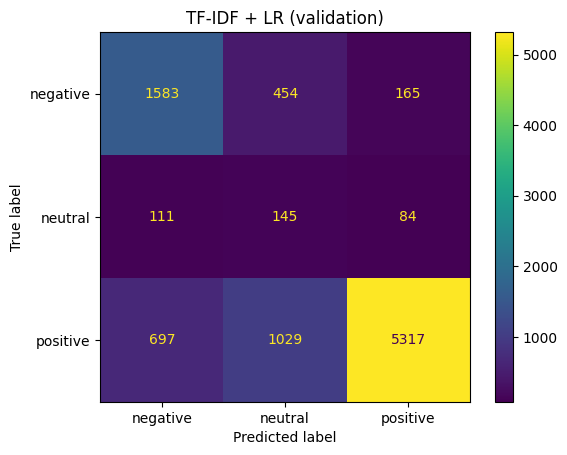

In [38]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score
import matplotlib.pyplot as plt

names = ["negative", "neutral", "positive"]
val_pred = lr.predict(X_val)

print(classification_report(y_val, val_pred, target_names=names, digits=3))
print("Macro-F1:", round(f1_score(y_val, val_pred, average="macro"), 3))

ConfusionMatrixDisplay(confusion_matrix(y_val, val_pred), display_labels=names).plot()
plt.title("TF-IDF + LR (validation)")
plt.show()

The baseline is evaluated on validation with per-class metrics and a confusion matrix. Accuracy looks decent only because positive reviews dominate, so macro-F1 is the main metric. Negative and positive classes are learned reasonably well, while neutral is weak.

---
Baseline validation-da hər sinif üzrə metrikalar və confusion matrix ilə qiymətləndirilir. Accuracy yalnız müsbət rəylər üstünlük təşkil etdiyi üçün yaxşı görünür, ona görə əsas metrik macro-F1-dir. Mənfi və müsbət siniflər kifayət qədər öyrənilir, neytral isə zəifdir.

In [39]:
import numpy as np

feat = np.array(tfidf.get_feature_names_out())
for i, name in enumerate(names):
    top = np.argsort(lr.coef_[i])[-15:][::-1]
    print(f"\n{name.upper()}:", ", ".join(feat[top]))


NEGATIVE: mir, ir, mir ,  pi, mi, pi,  pis, ləm,  pox, pox, 👎 , pis, ir , ib,  q

NEUTRAL:  3,  da ,  da, ğ ,  3 ,  2, eyil, mald,  u,  i , ? , 3 , 👈 , 🖐 , rmald

POSITIVE:  ə, əla,  əl, 👍 , ela ,  ela ,  əla, ️ , əla , lad, la , əl, elad,  əla ,  elad


The most influential character pieces are printed for each class. This checks whether the model learned meaningful patterns and not random noise. The patterns make sense, and emojis carry real signal, which confirms that keeping them was right.

---
Hər sinif üçün ən təsirli hərf parçaları çap olunur. Bu, modelin təsadüfi səs-küyü yox, mənalı nümunələri öyrənib-öyrənmədiyini yoxlayır. Nümunələr məntiqlidir və emojilər real siqnal daşıyır, bu da onları saxlamağın düzgün olduğunu təsdiqləyir.

In [40]:
baseline_val_macro_f1 = f1_score(y_val, val_pred, average="macro")
print("Baseline val macro-F1:", round(baseline_val_macro_f1, 3))

Baseline val macro-F1: 0.56


In [41]:
train_bal.to_csv("train_bal.csv", index=False)
val_df.to_csv("val.csv", index=False)

import os
print([f for f in os.listdir(".") if f.endswith(".csv")])

['test_clean.csv', 'train_labeled.csv', 'train_bal.csv', 'val.csv', 'train_clean.csv', 'test_labeled.csv']


## Transformer Fine-Tuning

In [42]:
from datasets import Dataset
from transformers import AutoTokenizer, DataCollatorWithPadding

MODEL = "xlm-roberta-base"
tok = AutoTokenizer.from_pretrained(MODEL)

def to_ds(df):
    ds = Dataset.from_pandas(df[["text", "label"]].reset_index(drop=True))
    return ds.map(lambda b: tok(b["text"], truncation=True, max_length=128),
                  batched=True, remove_columns=["text"])

train_ds = to_ds(train_bal)
val_ds   = to_ds(val_df)
collator = DataCollatorWithPadding(tok)

print(train_ds)
print(val_ds)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Map:   0%|          | 0/13926 [00:00<?, ? examples/s]

Map:   0%|          | 0/9585 [00:00<?, ? examples/s]

Dataset({
    features: ['label', 'input_ids', 'attention_mask'],
    num_rows: 13926
})
Dataset({
    features: ['label', 'input_ids', 'attention_mask'],
    num_rows: 9585
})


Texts are converted into token IDs that the XLM-R model can read. The tokenizer must match the model, and reviews are short, so a small maximum length is used. This step only prepares the data and does not train anything.

---
Mətnlər XLM-R modelinin oxuya biləcəyi token ID-lərinə çevrilir. Tokenizer modelə uyğun olmalıdır və rəylər qısa olduğu üçün kiçik maksimum uzunluq istifadə olunur. Bu addım yalnız datanı hazırlayır, heç nə öyrətmir.

In [43]:
print(train_bal["text"][0])
print(tok.convert_ids_to_tokens(train_ds[0]["input_ids"]))

Mukəmməl sistem qurmusuz. Ugurlar sizə
['<s>', '▁Muk', 'əm', 'mə', 'l', '▁sistem', '▁qur', 'mus', 'uz', '.', '▁Ugu', 'rlar', '▁sizə', '</s>']


One review is shown as tokens to see how the tokenizer works. A misspelled word is split into smaller pieces, but the model can still extract meaning from them. This is why heavy cleaning is not needed for the transformer.

---
Tokenizerin necə işlədiyini görmək üçün bir rəy tokenlər şəklində göstərilir. Səhv yazılmış söz kiçik parçalara bölünür, amma model bu parçalardan yenə məna çıxara bilir. Ona görə transformer üçün ağır təmizləmə lazım deyil.

In [44]:
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer
from sklearn.metrics import f1_score

id2label = {0: "negative", 1: "neutral", 2: "positive"}
label2id = {v: k for k, v in id2label.items()}

model = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=3, 
    id2label=id2label,label2id=label2id)

def compute_metrics(p):
    preds = np.argmax(p.predictions, axis=1)
    return {"macro_f1": f1_score(p.label_ids, preds, average="macro")}

args = TrainingArguments(output_dir="/kaggle/working/xlmr_out",num_train_epochs=3,
    learning_rate=2e-5,per_device_train_batch_size=32,per_device_eval_batch_size=64,
    eval_strategy="epoch",save_strategy="epoch",save_total_limit=1,
    load_best_model_at_end=True,metric_for_best_model="macro_f1",fp16=True,report_to="none",seed=42,)

trainer = Trainer(model=model, args=args,train_dataset=train_ds, eval_dataset=val_ds,
    processing_class=tok, data_collator=collator,compute_metrics=compute_metrics,)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


The pretrained XLM-R model gets a new 3-class output layer, and the training settings are defined. The best epoch is selected by validation macro-F1, not accuracy, because accuracy is misleading on imbalanced data. The warning about missing classifier weights is normal, because the new layer is learned during training.

---
Əvvəldən öyrədilmiş XLM-R modelinə yeni 3 sinifli çıxış qatı əlavə olunur və təlim ayarları təyin edilir. Ən yaxşı epox accuracy ilə yox, validation macro-F1 ilə seçilir, çünki balanssız datada accuracy aldadıcıdır. Çatışmayan classifier çəkiləri haqqında xəbərdarlıq normaldır, çünki yeni qat təlim zamanı öyrənilir.

In [45]:
trainer.train()

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Macro F1
1,No log,1.210531,0.514351
2,No log,1.149169,0.520911
3,1.510367,1.098664,0.559491


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=654, training_loss=1.4600556633158925, metrics={'train_runtime': 654.2023, 'train_samples_per_second': 63.861, 'train_steps_per_second': 1.0, 'total_flos': 2228486369639544.0, 'train_loss': 1.4600556633158925, 'epoch': 3.0})

The model is trained for a few epochs and checked on validation after each epoch. The validation score improved over the epochs and had not fully stopped improving, which means the model could still learn more with longer training.

---
Model bir neçə epox öyrədilir və hər epoxdan sonra validation-da yoxlanılır. Validation nəticəsi epoxlar boyu yaxşılaşdı və tam dayanmadı, yəni daha uzun təlimlə model hələ öyrənə bilər.

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


              precision    recall  f1-score   support

    negative      0.595     0.877     0.709      2202
     neutral      0.099     0.088     0.093       340
    positive      0.949     0.813     0.876      7043

    accuracy                          0.802      9585
   macro avg      0.548     0.593     0.559      9585
weighted avg      0.838     0.802     0.810      9585

XLM-R val macro-F1: 0.559 | baseline: 0.560


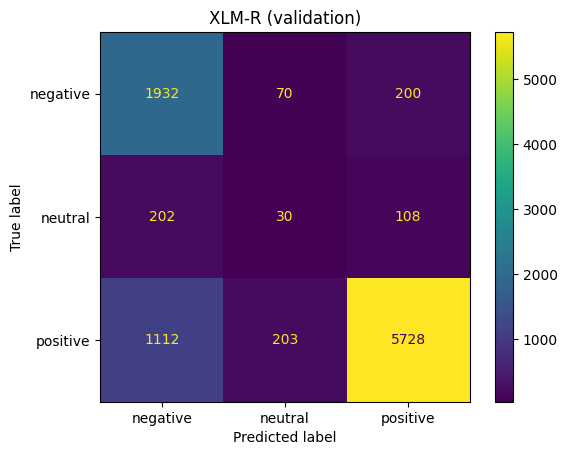

In [46]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score
import matplotlib.pyplot as plt

names = ["negative", "neutral", "positive"]
out = trainer.predict(val_ds)
val_pred = np.argmax(out.predictions, axis=1)
y_val = out.label_ids

print(classification_report(y_val, val_pred, target_names=names, digits=3))
print("XLM-R val macro-F1:", round(f1_score(y_val, val_pred, average="macro"), 3), "| baseline: 0.560")

ConfusionMatrixDisplay(confusion_matrix(y_val, val_pred), display_labels=names).plot()
plt.title("XLM-R (validation)")
plt.show()

The transformer is evaluated on the same validation data as the baseline for a fair comparison. It is slightly better on the negative and positive classes, but the neutral class remains weak. So the overall improvement over the baseline is small.

---
Ədalətli müqayisə üçün transformer baseline ilə eyni validation datasında qiymətləndirilir. Mənfi və müsbət siniflərdə bir qədər yaxşıdır, amma neytral sinif zəif qalır. Ona görə baseline ilə müqayisədə ümumi artım kiçikdir.

## Final Evaluation on Test

In [47]:
trainer.save_model("xlmr_sentiment")
tok.save_pretrained("xlmr_sentiment")

test_ds = to_ds(test_df)
out_t = trainer.predict(test_ds)
test_pred = np.argmax(out_t.predictions, axis=1)
y_test = out_t.label_ids

print(classification_report(y_test, test_pred, target_names=names, digits=3))
print("XLM-R TEST macro-F1:", round(f1_score(y_test, test_pred, average="macro"), 3))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Map:   0%|          | 0/31874 [00:00<?, ? examples/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


              precision    recall  f1-score   support

    negative      0.594     0.834     0.694      4076
     neutral      0.129     0.091     0.107       670
    positive      0.967     0.915     0.940     27128

    accuracy                          0.887     31874
   macro avg      0.563     0.613     0.580     31874
weighted avg      0.902     0.887     0.891     31874

XLM-R TEST macro-F1: 0.58


The model is saved and evaluated on the test set for the first time. Test was not used for training or for any choice, so this is the most honest result. Accuracy is high mainly because most test reviews are positive, so macro-F1 and per-class scores are the real indicators.

---
Model saxlanılır və test dəstində ilk dəfə qiymətləndirilir. Test nə təlimdə, nə də hər hansı seçimdə istifadə olunmayıb, ona görə bu, ən dürüst nəticədir. Accuracy əsasən test rəylərinin çoxu müsbət olduğu üçün yüksəkdir, real göstəricilər isə macro-F1 və sinif nəticələridir.

In [48]:
seen = test_df["seen_in_train"].values

for title, mask in [("Seen in train", seen), ("Unseen (new reviews)", ~seen)]:
    print(f"\n=== {title}: {mask.sum()} reviews ===")
    print(classification_report(y_test[mask], test_pred[mask], target_names=names, digits=3))


=== Seen in train: 16592 reviews ===
              precision    recall  f1-score   support

    negative      0.649     0.521     0.578       493
     neutral      0.000     0.000     0.000       121
    positive      0.979     0.992     0.985     15978

    accuracy                          0.971     16592
   macro avg      0.543     0.504     0.521     16592
weighted avg      0.962     0.971     0.966     16592


=== Unseen (new reviews): 15282 reviews ===
              precision    recall  f1-score   support

    negative      0.590     0.877     0.705      3583
     neutral      0.129     0.111     0.119       549
    positive      0.947     0.805     0.870     11150

    accuracy                          0.797     15282
   macro avg      0.555     0.598     0.565     15282
weighted avg      0.834     0.797     0.804     15282



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


The test set is evaluated in two parts: reviews that also exist in the train data and completely new reviews. The first part is mostly short common phrases, which inflates accuracy. The new reviews show how the model works on unseen text, so they are the more realistic measure.

---
Test iki hissədə qiymətləndirilir - train datasında da olan rəylər və tamamilə yeni rəylər. Birinci hissə əsasən qısa ümumi ifadələrdir və accuracy-ni şişirdir. Yeni rəylər modelin görmədiyi mətndə necə işlədiyini göstərir, ona görə daha real ölçüdür.

In [49]:
X_test = tfidf.transform(test_df["text"])
lr_pred = lr.predict(X_test)

for title, mask in [("Full test", np.ones(len(y_test), bool)), ("Unseen only", ~seen)]:
    b = f1_score(y_test[mask], lr_pred[mask], average="macro")
    x = f1_score(y_test[mask], test_pred[mask], average="macro")
    print(f"{title}: baseline macro-F1 = {b:.3f} | XLM-R macro-F1 = {x:.3f}")

Full test: baseline macro-F1 = 0.578 | XLM-R macro-F1 = 0.580
Unseen only: baseline macro-F1 = 0.554 | XLM-R macro-F1 = 0.565


The baseline is also measured on the same test data to compare both models fairly. The two models perform almost the same. This means the transformer did not clearly beat the simple model in this setup.

---
İki modeli ədalətli müqayisə etmək üçün baseline də eyni test datasında ölçülür. İki model demək olar ki, eyni nəticə göstərir. Bu o deməkdir ki, bu şəraitdə transformer sadə modeli aydın şəkildə üstələmədi.

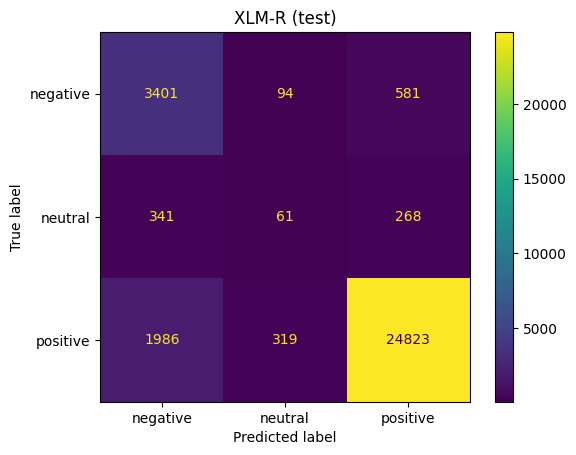

In [50]:
ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred), display_labels=names).plot()
plt.title("XLM-R (test)")
plt.show()

The confusion matrix shows which classes the model confuses. The neutral class is mixed with both negative and positive, and many positive reviews are predicted as negative. This fits the earlier observation that neutral reviews are ambiguous and that some labels are noisy.

---
Confusion matrix modelin hansı sinifləri qarışdırdığını göstərir. Neytral sinif həm mənfi, həm müsbətlə qarışır və bir çox müsbət rəy mənfi kimi təsnif olunur. Bu, neytral rəylərin qeyri-müəyyən olması və bəzi etiketlərin "səs-küylü" olması haqqında əvvəlki müşahidəyə uyğundur.

In [51]:
from scipy.special import softmax

conf = softmax(out_t.predictions, axis=1).max(axis=1)
err = test_df.assign(pred=test_pred, conf=conf)
wrong = err[err["label"] != err["pred"]].sort_values("conf", ascending=False)

print("Total errors:", len(wrong))
wrong[["text", "score", "label", "pred", "conf"]].head(20)

Total errors: 3589


,text,score,label,pred,conf
29152,Çox beyedimm..👍👍👆,1,0,2,0.977149
15933,Əla tətbiqdi bəyəndim 👍👍,1,0,2,0.976836
294,Superrddi👍,1,0,2,0.976690
26742,əladır.👍💖😍,3,1,2,0.976299
27163,Super 👍 👍 👍 👍,1,0,2,0.975904
23054,Qəşəq proqram💪🏻💪🏻,1,0,2,0.975587
18772,əla super👍,1,0,2,0.975340
14206,cox gozel tetbiqdi raziyam,2,0,2,0.975314
16747,Əla ve kefiyetli,1,0,2,0.975245
22305,Ela proqramdi tesekkurler,3,1,2,0.974629


The errors where the model was most confident are listed and read. Most of them are clear praise texts that have a low star rating, so the model is right and the label is wrong. This means the test scores probably understate the model's real quality, and the labels were not changed.

---
Modelin ən əmin olduğu səhvlər sıralanır və oxunur. Onların çoxu aşağı ulduzla verilmiş aydın tərif mətnləridir, yəni model haqlıdır, etiket isə yanlışdır. Bu, test nəticələrinin modelin real keyfiyyətini ehtimal ki, az göstərdiyini bildirir və etiketlər dəyişdirilmədi.

In [65]:
rep = classification_report(y_test, test_pred, target_names=names, output_dict=True)
pd.DataFrame(rep).T.round(3).to_csv("eval_test_report.csv")

fig, ax = plt.subplots()
ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred), display_labels=names).plot(ax=ax)
ax.set_title("XLM-R (test)")
fig.savefig("eval_confusion_matrix_test.png", dpi=150, bbox_inches="tight")
plt.close(fig)

rows = []
for title, mask in [("Full test", np.ones(len(y_test), bool)), ("Unseen only", ~seen)]:
    rows.append({
        "subset": title, "n": int(mask.sum()),
        "baseline_macro_f1": round(f1_score(y_test[mask], lr_pred[mask], average="macro"), 3),
        "xlmr_macro_f1": round(f1_score(y_test[mask], test_pred[mask], average="macro"), 3),
    })
pd.DataFrame(rows).to_csv("eval_comparison.csv", index=False)
print(pd.DataFrame(rows))

        subset      n  baseline_macro_f1  xlmr_macro_f1
0    Full test  31874              0.578          0.580
1  Unseen only  15282              0.554          0.565


The test results are saved as files for the evaluation pack: the per-class report, the confusion matrix image, and the baseline vs XLM-R comparison. This makes the evaluation easy to check without re-running the notebook. The comparison is given for the full test set and for the unseen reviews only.

---
Test nəticələri evaluation pack üçün fayl kimi saxlanılır: hər sinif üzrə hesabat, confusion matrix şəkli və baseline ilə XLM-R müqayisəsi. Bu, qiymətləndirməni notebook-u yenidən işlətmədən yoxlamağa imkan verir. Müqayisə həm tam test, həm də yalnız yeni rəylər üçün verilir.

## Topic Modeling

In [66]:
def pick(df, label, n=10000):
    d = df[(df["label"] == label) & (df["text"].str.split().str.len() >= 4)]
    return d.sample(min(len(d), n), random_state=42)["text"].tolist()

neg_docs = pick(train_df, 0)
pos_docs = pick(train_df, 2)

print("negative:", len(neg_docs), "| positive:", len(pos_docs))
print(neg_docs[:3])
print(pos_docs[:3])

negative: 10000 | positive: 10000
['Bəyən mədim deyir nömrəniz qeydiyyata deyil xahiş edirəm bir kömək edin', 'salam men 1 inci qeydiyyatdan kecdiyim nomremi qirmiwam indi kecmek istirem alinmir yazilirki xeta serverle elaqe mumkun olmadi ama ki sinan nomremi yaziram deyirki size sms vaistesi ile size kod gonderilecem nieki bele olmazaxi mende mb ile yukliremde', 'Çox pis sifariş verdiyde başqa qiymət gəlib çatdıqda başqa qiymət göstərir']
['Çox super çox razı qaldım', 'Bankınıza müraciət etdim və qısa bir zaman ərzində ehtiyacım olan məbləğdə kredit aldım.Üstəlik mənə Tam Kart da hədiyyə etdilər. Təşəkkür edirəm!', 'Her bir şeyi beyenirem amma 1 seyden basqa niyə karta atanda 1 man atmaliyiq? Məndə 99 qəpik var ata bilmirəm kartıma deli olmusam']


Negative and positive reviews are selected separately for topic modeling, using only reviews with at least four words. Separate models answer two different questions: what users complain about and what they praise. Very short reviews like `Əla` do not form meaningful topics, and neutral is too small to model.

---
Mövzu modelləşdirməsi üçün mənfi və müsbət rəylər ayrıca seçilir, yalnız ən azı dörd sözlü rəylər götürülür. Ayrı modellər iki fərqli suala cavab verir, istifadəçilər nədən şikayət edir və nəyi tərifləyir. `Əla` kimi çox qısa rəylər mənalı mövzu yaratmır, neytral sinif isə modelləşdirmək üçün çox kiçikdir.

In [67]:
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer

emb_model = SentenceTransformer("sentence-transformers/LaBSE", device="cuda")

neg_emb = emb_model.encode(neg_docs, batch_size=128, show_progress_bar=True)
pos_emb = emb_model.encode(pos_docs, batch_size=128, show_progress_bar=True)

print(neg_emb.shape, pos_emb.shape)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

(10000, 768) (10000, 768)


Each review is converted into a vector that represents its meaning, using the multilingual LaBSE model. Reviews with similar meaning get similar vectors, and topic grouping is based on this similarity. The model is used as it is and is not trained.

---
Hər rəy çoxdilli LaBSE modeli ilə mənasını təmsil edən vektora çevrilir. Mənası oxşar olan rəylər oxşar vektor alır və mövzu qruplaşdırması bu oxşarlığa əsaslanır. Model olduğu kimi istifadə olunur və öyrədilmir.

In [68]:
from bertopic import BERTopic
from sklearn.feature_extraction.text import CountVectorizer
from umap import UMAP
from hdbscan import HDBSCAN

stop = ["bu","bir","və","ve","ki","da","də","de","amma","ama","çox","cox","mən","men",
        "nə","ne","var","olar","hər","her","üçün","ucun","ilə","ile","sonra","daha",
        "kimi","mənim","menim","bunu","onu","ona","olan","edir","edirəm","edirem"]

def run_topics(docs, emb):
    tm = BERTopic(language="multilingual",umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=42),
        hdbscan_model=HDBSCAN(min_cluster_size=60, metric="euclidean", prediction_data=True),
        vectorizer_model=CountVectorizer(stop_words=stop, ngram_range=(1, 2), min_df=5),
        top_n_words=8,verbose=False,)
    
    topics, _ = tm.fit_transform(docs, embeddings=emb)
    return tm, topics

neg_tm, neg_topics = run_topics(neg_docs, neg_emb)
neg_tm.get_topic_info()[["Topic", "Count", "Name"]].head(20)

,Topic,Count,Name
0,-1,3380,-1_pul_pis_olmur_heç
1,0,3120,0_pis_olmur_proqram_tez
2,1,949,1_salam_olmasa_nece_bilmirəm
3,2,654,2_taksi_manat_sifariş_azn
4,3,444,3_niye_niyə_işləmir_olmur
5,4,317,4_reklam_sizin_elan_bolt
6,5,301,5_gündü_gündür_saat_gb
7,6,152,6_ulduz_ulduzda_düşmür_coxdu
8,7,144,7_idi_yaxşı idi_yaxşı_indi
9,8,120,8_internet_nternet_ola_interneti


BERTopic groups the negative reviews into topics and gives keywords for each one. A multilingual setting keeps Azerbaijani letters, and a small stopword list was made by hand because no ready list exists. Many reviews remain without a topic and one large topic is very general, which is normal for short and noisy texts.

---
BERTopic mənfi rəyləri mövzulara qruplaşdırır və hər biri üçün açar sözlər verir. Çoxdilli ayar Azərbaycan hərflərini saxlayır, hazır siyahı olmadığı üçün kiçik stopword siyahısı əl ilə hazırlanıb. Çoxlu rəy mövzusuz qalır və bir böyük mövzu çox ümumidir, bu isə qısa və "səs-küylü" mətnlər üçün normaldır.

In [69]:
pos_tm, pos_topics = run_topics(pos_docs, pos_emb)
pos_tm.get_topic_info()[["Topic", "Count", "Name"]].head(20)

,Topic,Count,Name
0,-1,3481,-1_əla_super_yaxşı_gözəl
1,0,1951,0_salam_necə_nece_kart
2,1,594,1_olsa_olardı_yaxşı_olardi
3,2,522,2_proqramdır_proqramdi_proqram_gözəl
4,3,353,3_şey_sey_tapa_şeyi
5,4,292,4_bank_abb_ən_kapital bank
6,5,282,5_rahat_asan_sərfəli_serfeli
7,6,255,6_bəyəndim_geldi_beyendim_xoşuma
8,7,247,7_yaxşı_proqram_olsa_proqramdır
9,8,222,8_olun_sağolun_təşəkkür_sağ olun


The same process is applied to the positive reviews so that praise topics are seen separately from complaints. Positive topics are more general than negative ones, because people often praise without giving details. Some topics also contain questions and complaints even though the stars are high.

---
Eyni proses müsbət rəylərə tətbiq olunur ki, tərif mövzuları şikayətlərdən ayrıca görünsün. Müsbət mövzular mənfidən daha ümumidir, çünki insanlar çox vaxt təfərrüat vermədən tərifləyir. Bəzi mövzularda ulduzlar yüksək olsa da sual və şikayətlər də var.

In [70]:
def show_topics(tm, docs, topics, k=5, n=3):
    info = tm.get_topic_info()
    for t in info[info["Topic"] >= 0]["Topic"].head(k):
        docs_t = pd.Series([d for d, tp in zip(docs, topics) if tp == t])
        print(f"\n=== Topic {t} ({len(docs_t)} reviews) ===")
        for d in docs_t.sample(min(n, len(docs_t)), random_state=1):
            print("-", d[:150])

In [71]:
show_topics(neg_tm, neg_docs, neg_topics)


=== Topic 0 (3120 reviews) ===
- Mən bu tətbiqi yüklədim və məndə deyirki siz qeydiyatdan keçmisiz ancaq mən qeydiyatdan keçəmişəm
- proqrami indi yukləmişəm. qeydiyyatsız ödəniş et-in üstünə basıram açılmır. çıxışı vururam açılıbmış kimi düşür mövzulardan çıxır. 64kilobit /sürətləd
- Nömreni yazıram xeta yazılır elece

=== Topic 1 (949 reviews) ===
- Salam bugun beşdene sifariş vermişem suruculeriniz hamisi atqaz verir gelmekden imtina edirler
- Sabağız xeyir mən neynirəm nntv nı Zəhmət olmasa düzgün şey verin
- Salam, men bunu qeydiyatdan kecmisem amma, bu kecdiyim qeydiyati sexsiyet vesiqesini ve sayre silmek isteyirem. Basqa sexsiyet vesiqesi ile giris etme

=== Topic 2 (654 reviews) ===
- 3 kilometrlik yolu aparib herleyib 15 kilometrlik yolnan aparir. Islemeyi 0
- Cox qarisiq. 👎 2 gundu kesbekin yerini axtariram tapa bilmedim sildim. Azercelin A cart tetbiqi superdi. Kesbek hemen odenisin yaninda gorunur
- Tupurum bele wirkete taxi sifariw etmiwem afdomabil yaxinlasib.baxiram ma

A few real reviews from the largest negative topics are read to understand and name them. The main complaints are about login and registration, payment and app errors, taxi service, and advertising messages. One topic is a writing-style group (reviews starting with `Salam`) and not a content topic.

---
Ən böyük mənfi mövzulardan bir neçə real rəy oxunur ki, onları anlayıb adlandıraq. Əsas şikayətlər giriş və qeydiyyat, ödəniş və proqram xətaları, taksi xidməti və reklam mesajları ilə bağlıdır. Bir mövzu məzmun yox, yazı üslubu qrupudur (`Salam` ilə başlayan rəylər).

In [72]:
show_topics(pos_tm, pos_docs, pos_topics)


=== Topic 0 (1951 reviews) ===
- Mənim balansımdan hər dəfə kontur yükləyəndə 20qəp 50 qəp 60 qəp. Çıxır gündə 3. 4 dəfə Bunun üçün nə edə bilərəm ?? Kömək etsəz sevinərəm
- Bu ne ucundur bilen var?.
- Hal hazirda mende 1 hefteden coxdur ki proq ram iwlemir nomre qeydiyyatidi kart deyil sebeb nedi ?

=== Topic 1 (594 reviews) ===
- Daimi olsa idi yaxşı oldı.
- Çox əladı başqa nömrəyə balans yükləmək olsa dahada yaxşı olar
- Əla amma xətalar tez tez rast gəlinir

=== Topic 2 (522 reviews) ===
- Ideal tətbiq. Işlərinizdə uğurlar.
- maragli proqramdi xosum gelir. 👍
- Əla proqramdır. Ödəmələri də anında köçürmək olur.👍

=== Topic 3 (353 reviews) ===
- İş elanları tapmağda köməkliy edir
- hər şey çox gözəl.uqurlarınız bol olsun.istifadəçiniz olaraq bizdə qürur duyaq sizinlə
- Mənim bütün işlərim burdan keçir çox gozəldi

=== Topic 4 (292 reviews) ===
- Ən super Bank mənim üçün,işçi heyəti gülərüz,savadlı,müştəri məmnuniyyəti əla,proqram rahatlığı super,uğurlar Sizlərə
- Razıyam, bir cox ba

A few real reviews from the largest positive topics are read to understand and name them. Users mostly praise the app in general, its convenience, bank service and staff, and also make suggestions. The largest group is not really praise, but questions and problems with a high star rating, which matches the label noise noticed earlier.

---
Ən böyük müsbət mövzulardan bir neçə real rəy oxunur ki, onları anlayıb adlandıraq. İstifadəçilər əsasən proqramı ümumi şəkildə, rahatlığını, bank xidmətini və işçiləri tərifləyir, həm də təkliflər verir. Ən böyük qrup əslində tərif deyil, yüksək ulduzla verilmiş sual və problemlərdir, bu da əvvəl müşahidə olunan etiket səs-küyünə uyğundur.

In [73]:
def topic_table(tm):
    info = tm.get_topic_info()[["Topic", "Count", "Name"]].copy()
    info["Share_%"] = (info["Count"] / info["Count"].sum() * 100).round(1)
    return info

In [74]:
neg_table = topic_table(neg_tm)
pos_table = topic_table(pos_tm)

print("Negative, total:", neg_table["Count"].sum(), "| topic count:", (neg_table["Topic"] >= 0).sum())
print("Positive, total:", pos_table["Count"].sum(), "| topic count:", (pos_table["Topic"] >= 0).sum())

Negative, total: 10000 | topic count: 14
Positive, total: 10000 | topic count: 25


In [75]:
neg_table.to_csv("topics_negative.csv", index=False)
pos_table.to_csv("topics_positive.csv", index=False)

Topics of negative and positive reviews are compared. Negative topics describe concrete problems: login and registration errors, payment and app errors, taxi service, and advertising messages. Positive topics are more general (praise, thanks, recommendations, suggestions), and a part of them reports problems despite a high star rating. This comparison is based on reading real reviews from the five largest topics of each sentiment; the other topics are described only by their keywords.

---
Mənfi və müsbət rəylərin mövzuları müqayisə edilir. Mənfi mövzular konkret problemləri təsvir edir: giriş və qeydiyyat xətaları, ödəniş və proqram xətaları, taksi xidməti və reklam mesajları. Müsbət mövzular daha ümumidir (tərif, təşəkkür, tövsiyə, təkliflər), bir hissəsi isə yüksək ulduza baxmayaraq problem bildirir. Bu müqayisə hər sentimentin ən böyük beş mövzusundan oxunan real rəylərə əsaslanır; qalan mövzular yalnız açar sözlərlə təsvir olunur.

## Web Demo

In [77]:
import torch, gradio as gr
from transformers import pipeline

clf = pipeline("text-classification", model="xlmr_sentiment", tokenizer="xlmr_sentiment",
               top_k=None, device=0 if torch.cuda.is_available() else -1)

def predict(text):
    res = clf(clean(text))
    if isinstance(res[0], list):
        res = res[0]
    return {r["label"]: float(r["score"]) for r in res}

demo = gr.Interface(
    fn=predict,
    inputs=gr.Textbox(lines=3, label="Review (Azerbaijani)"),
    outputs=gr.Label(num_top_classes=3, label="Sentiment"),
    title="Azerbaijani Review Sentiment (XLM-R)",
    examples=["Əla proqramdır, çox razıyam 👍", "Proqram açılmır, qeydiyyatdan keçə bilmirəm", "Pis deyil amma bir az yavaşdır"],
)
demo.launch(share=True)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://f104680ac4366a7460.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


The saved XLM-R model is deployed as a simple Gradio web demo: the user types a review, the same `clean()` function is applied, and the model returns the probability of each class. This shows that the whole pipeline works on raw text, not only on prepared datasets. The demo is weaker on neutral reviews, which matches the evaluation results.

---
Saxlanmış XLM-R modeli sadə Gradio veb demosu kimi yerləşdirilir: istifadəçi rəy yazır, eyni `clean()` funksiyası tətbiq olunur və model hər sinfin ehtimalını qaytarır. Bu, bütün pipeline-ın hazır datasetdə yox, xam mətndə də işlədiyini göstərir. Demo neytral rəylərdə daha zəifdir, bu da qiymətləndirmə nəticələrinə uyğundur.